# Capital allocation across strategy sleeves
Weights from 2022–2023 only (`alloc/allocate.py`); idle capital earns SOFR (New York Fed). Figures follow a NeurIPS-style plot guide via `research_style.py`.

In [1]:
import sys, pathlib, numpy as np, pandas as pd, matplotlib.pyplot as plt
R = pathlib.Path.cwd().resolve().parents[1]; sys.path.insert(0, str(R))
import research_style as rs; rs.setup()
A = R / 'alloc'; F = A / 'figures'
W = pd.read_csv(A / 'weights_static.csv', index_col=0); C = pd.read_csv(A / 'sleeve_corr_dev.csv', index_col=0)
P = pd.read_csv(A / 'portfolio_daily_excess.csv', index_col=0); S = pd.read_csv(A / 'allocation_summary.csv')
code = lambda lab: lab.split()[0]

**Message:** shrinkage Markowitz concentrates on five sleeves with positive 2022–23 means, while minimum variance loads on the low-volatility straddle sleeves.

PosixPath('/Users/nigelli/Desktop/lp work/alloc/figures/fig18_alloc_weights.png')

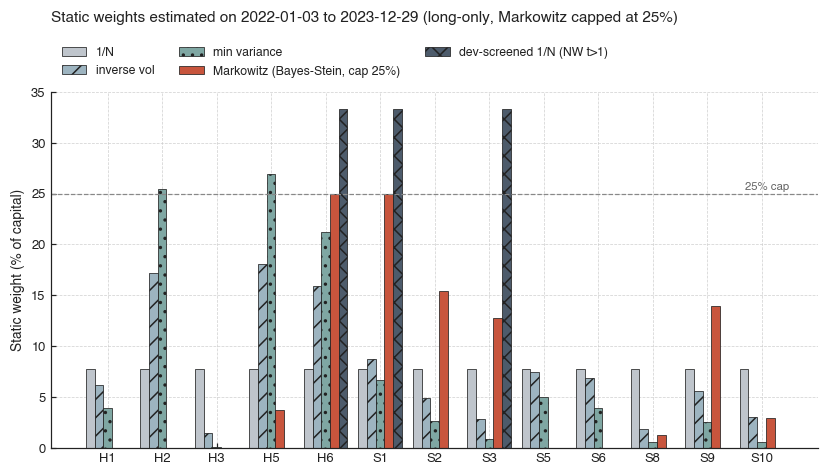

In [2]:
meth = ['1/N', 'inverse vol', 'min variance', 'Markowitz (Bayes-Stein, cap 25%)', 'dev-screened 1/N (NW t>1)']
fig, ax = plt.subplots(figsize=(9, 4.2)); x = np.arange(len(W)); bw = .16
for j, m in enumerate(meth):
    b = ax.bar(x + (j - 2) * bw, W[m] * 100, bw, label=m, edgecolor=rs.INK, linewidth=.5,
               hatch=['', '//', '..', '', 'xx'][j], color=['#BFC5CC', '#9DB4C0', '#7FA7A3', rs.OOS_COL, '#4D5B6B'][j])
ax.set_xticks(x, [code(l) for l in W.index]); ax.set_ylabel('Static weight (% of capital)')
ax.set_title('Static weights estimated on 2022-01-03 to 2023-12-29 (long-only, sum <= 100%)')
ax.legend(ncol=3, loc='lower left', bbox_to_anchor=(0, 1.01), frameon=False); ax.set_title('Static weights estimated on 2022-01-03 to 2023-12-29 (long-only, Markowitz capped at 25%)', pad=46)
ax.axhline(25, ls='--', color='#888888', lw=.8); ax.text(len(W) - .5, 25.4, '25% cap', ha='right', fontsize=7.5, color='#666666')
rs.save(fig, F / 'fig18_alloc_weights.png')

**Message:** sleeve returns were close to uncorrelated in 2022–23, so combining them reduces volatility.

PosixPath('/Users/nigelli/Desktop/lp work/alloc/figures/fig19_alloc_corr.png')

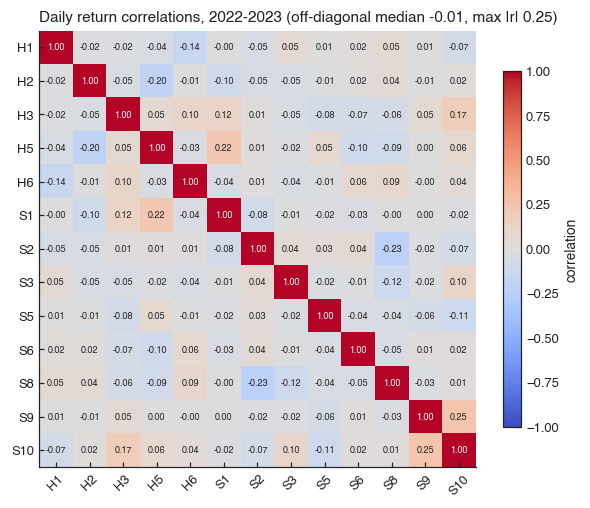

In [3]:
fig, ax = plt.subplots(figsize=(6.4, 5.6)); M = C.values
im = ax.imshow(M, cmap='coolwarm', vmin=-1, vmax=1); ax.grid(False)
labs = [code(l) for l in C.index]; ax.set_xticks(range(len(labs)), labs, rotation=45); ax.set_yticks(range(len(labs)), labs)
for i in range(len(labs)):
    for j in range(len(labs)):
        ax.text(j, i, f'{M[i, j]:.2f}', ha='center', va='center', fontsize=6, color='white' if abs(M[i, j]) > .6 else rs.INK)
off = M[~np.eye(len(M), dtype=bool)]
ax.set_title(f'Daily return correlations, 2022-2023 (off-diagonal median {np.median(off):.2f}, max |r| {np.abs(off).max():.2f})')
fig.colorbar(im, ax=ax, shrink=.75, label='correlation'); rs.save(fig, F / 'fig19_alloc_corr.png')

**Message:** in 2024 the 1/N and walk-forward Markowitz books earned about 4 percentage points over SOFR; minimum variance earned about SOFR.

                                         method     schedule  ann_total  ann_excess  sharpe  max_dd
                                            1/N       static     0.0991      0.0421  2.0026 -0.0089
                                            1/N walk-forward     0.0991      0.0421  2.0026 -0.0089
                                    inverse vol       static     0.0591      0.0049  0.4834 -0.0045
                                    inverse vol walk-forward     0.0599      0.0057  0.5637 -0.0043
                                   min variance       static     0.0516     -0.0023 -0.4093 -0.0023
                                   min variance walk-forward     0.0512     -0.0027 -0.5255 -0.0022
               Markowitz (Bayes-Stein, cap 25%)       static     0.0931      0.0367  1.8890 -0.0074
               Markowitz (Bayes-Stein, cap 25%) walk-forward     0.1043      0.0469  2.0706 -0.0089
                      dev-screened 1/N (NW t>1)       static     0.1005      0.0435  1.6269 -0.0113


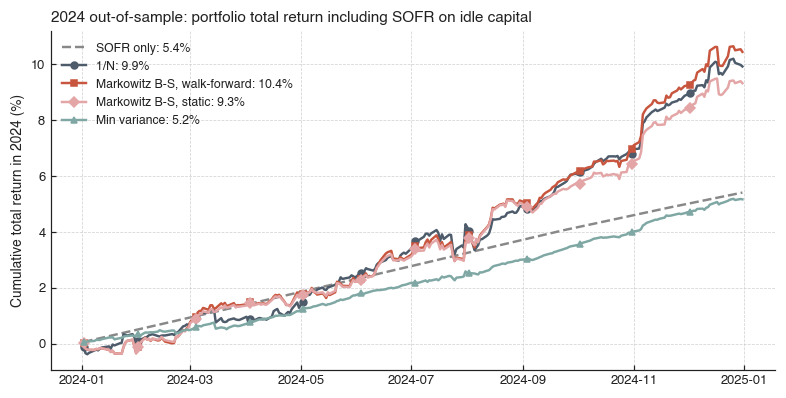

In [4]:
d = pd.to_datetime(P.index.astype(str)); P.index = d
show = {'1/N | static': ('1/N', '#4D5B6B', 'o'), 'Markowitz (Bayes-Stein, cap 25%) | walk-forward': ('Markowitz B-S, walk-forward', rs.OOS_COL, 's'),
        'Markowitz (Bayes-Stein, cap 25%) | static': ('Markowitz B-S, static', '#E3A5A5', 'D'), 'min variance | static': ('Min variance', '#7FA7A3', '^')}
fig, ax = plt.subplots(figsize=(8.5, 4)); y = P.loc['2024']
sofr = (1 + y['sofr']).cumprod() - 1
ax.plot(sofr.index, sofr * 100, '--', color='#888888', label=f'SOFR only: {sofr.iloc[-1]*100:.1f}%', marker=None)
for col, (lab, c, mk) in show.items():
    tot = (1 + y[col] + y['sofr']).cumprod() - 1
    ax.plot(tot.index, tot * 100, color=c, marker=mk, markevery=21, label=f'{lab}: {tot.iloc[-1]*100:.1f}%')
ax.set_ylabel('Cumulative total return in 2024 (%)'); ax.set_title('2024 out-of-sample: portfolio total return including SOFR on idle capital')
ax.legend(loc='upper left'); rs.save(fig, F / 'fig20_alloc_2024.png')
print(S[S.period.str.startswith('2024')][['method', 'schedule', 'ann_total', 'ann_excess', 'sharpe', 'max_dd']].round(4).to_string(index=False))